##  6.To perform an analyze of Gradient decienent method

In [1]:
# Name: Mayuri Sheshrao Rathod 
# Roll No.: 51
# Branch: B.E. CSE (Data Science)
# Year: Final Year
# Semester: VII
# Academic Year: 2026–27
# Dataset: Breast Cancer Wisconsin (Diagnostic) Dataset

## 1. Install KaggleHub Library

In [2]:
!pip install kagglehub

## 2. Download Dataset from Kaggle

In [3]:
import kagglehub

path = kagglehub.dataset_download("camnugent/california-housing-prices")

print(path)

100%|██████████| 400k/400k [00:01<00:00, 300kB/s]

Extracting files...
C:\Users\USER VICTUS\.cache\kagglehub\datasets\camnugent\california-housing-prices\versions\1


## 3. Check Dataset Files

In [4]:
import os

print(os.listdir(path))

['housing.csv']


## 4. Load the Dataset

In [5]:
import pandas as pd

df = pd.read_csv(path + "/housing.csv")

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,NEAR BAY
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,NEAR BAY
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,NEAR BAY
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,NEAR BAY
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,NEAR BAY


## 5. Explore the Dataset

In [6]:
print("Shape of dataset:", df.shape)

print("\nColumn names:")
print(df.columns)

Shape of dataset: (20640, 10)

Column names:
Index(['longitude', 'latitude', 'housing_median_age', 'total_rooms',
       'total_bedrooms', 'population', 'households', 'median_income',
       'median_house_value', 'ocean_proximity'],
      dtype='str')


## 6. Check Missing Values

In [7]:
print(df.isnull().sum())

longitude               0
latitude                0
housing_median_age      0
total_rooms             0
total_bedrooms        207
population              0
households              0
median_income           0
median_house_value      0
ocean_proximity         0
dtype: int64


## 7. Handle Missing Values

In [8]:
df = df.dropna()

print("New shape:", df.shape)

New shape: (20433, 10)


## 8. Convert Categorical Data

In [9]:
df = pd.get_dummies(df, columns=['ocean_proximity'], drop_first=True)

df.head()

,longitude,latitude,housing_median_age,total_rooms,total_bedrooms,population,households,median_income,median_house_value,ocean_proximity_INLAND,ocean_proximity_ISLAND,ocean_proximity_NEAR BAY,ocean_proximity_NEAR OCEAN
0,-122.23,37.88,41.0,880.0,129.0,322.0,126.0,8.3252,452600.0,False,False,True,False
1,-122.22,37.86,21.0,7099.0,1106.0,2401.0,1138.0,8.3014,358500.0,False,False,True,False
2,-122.24,37.85,52.0,1467.0,190.0,496.0,177.0,7.2574,352100.0,False,False,True,False
3,-122.25,37.85,52.0,1274.0,235.0,558.0,219.0,5.6431,341300.0,False,False,True,False
4,-122.25,37.85,52.0,1627.0,280.0,565.0,259.0,3.8462,342200.0,False,False,True,False


## 9. Separate Features and Target Variable

In [10]:
X = df.drop('median_house_value', axis=1)
y = df['median_house_value']

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (20433, 12)
Target shape: (20433,)


## 10. Split the Dataset

In [11]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16346, 12)
Testing data: (4087, 12)


## 10. Split the Dataset

In [12]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)

print("Training data:", X_train.shape)
print("Testing data:", X_test.shape)

Training data: (16346, 12)
Testing data: (4087, 12)


## 11. Feature Scaling

In [13]:
from sklearn.preprocessing import StandardScaler

scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

print("Feature scaling completed successfully.")

Feature scaling completed successfully.


## 12. Apply Gradient Descent

In [14]:
from sklearn.linear_model import SGDRegressor

model = SGDRegressor(
    max_iter=1000,
    learning_rate='invscaling',
    random_state=42
)

model.fit(X_train, y_train)

print("Gradient Descent model trained successfully.")

Gradient Descent model trained successfully.


## 13. Make Predictions

In [15]:
y_pred = model.predict(X_test)

print("Predictions:")
print(y_pred[:10])

Predictions:
[  2436783.96697164   1294928.69383493  -3710251.52873737
   4431201.19820854 -34847610.22573918   6618874.56215438
 -13300353.60513908   3062958.3986986    8915393.67625698
  17339709.73802188]


## 14. Calculate Mean Squared Error

In [16]:
from sklearn.metrics import mean_squared_error

mse = mean_squared_error(y_test, y_pred)

print("Mean Squared Error:", mse)

Mean Squared Error: 1.0238035587125687e+21


## 15. Calculate Root Mean Squared Error

In [17]:
import numpy as np

rmse = np.sqrt(mse)

print("Root Mean Squared Error:", rmse)

Root Mean Squared Error: 31996930457.663727


## 16. Calculate R² Score

In [18]:
from sklearn.metrics import r2_score

r2 = r2_score(y_test, y_pred)

print("R² Score:", r2)

R² Score: -74865815283.65382


## 17. Actual vs Predicted Values

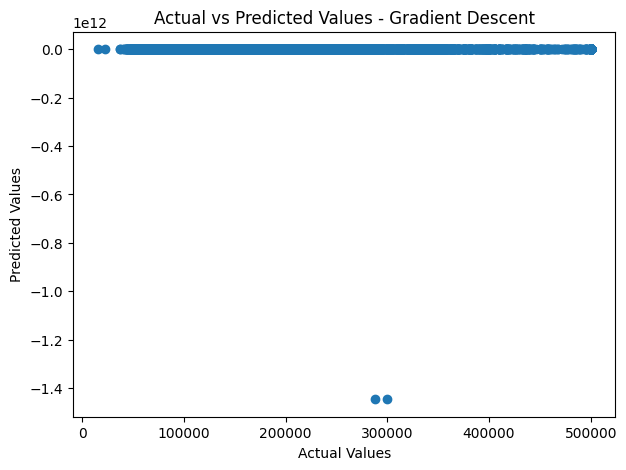

In [19]:
import matplotlib.pyplot as plt

plt.figure(figsize=(7, 5))

plt.scatter(y_test, y_pred)

plt.xlabel('Actual Values')
plt.ylabel('Predicted Values')
plt.title('Actual vs Predicted Values - Gradient Descent')
plt.show()